In [1]:
import csv 
import numpy as np 
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

In [2]:

def read_data_from_csv(filename):
    t_log = []
    energy_log = []
    charged_nodes_positions_log = []
    with open(filename, mode='r') as file:
        reader = csv.reader(file)
        headings = next(reader)  
        for row in reader:
            t_log.append(float(row[0]))
            energy_log.append(float(row[1]))
            num_charges = (len(row) - 2) // 2
            charged_positions = []
            for i in range(num_charges):
                x = float(row[2 + 2*i])
                y = float(row[3 + 2*i])
                charged_positions.append((x, y))
            charged_nodes_positions_log.append(charged_positions)
    return t_log, energy_log, charged_nodes_positions_log

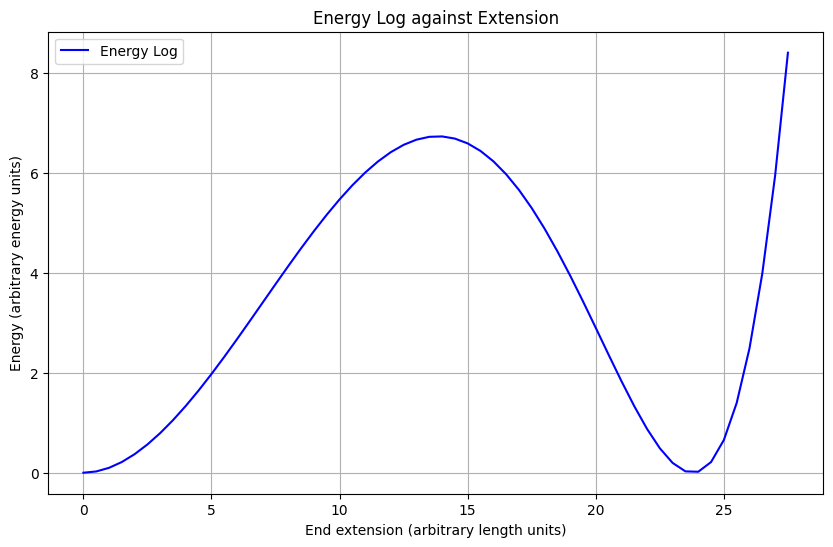

In [3]:
t_log, energy_log, charged_nodes_positions_log = read_data_from_csv("charge_distance_data.csv")
t_log = np.array(t_log)
energy_log = np.array(energy_log)

plt.figure(figsize=(10, 6))
plt.plot(t_log, energy_log, label='Energy Log', color='blue')
plt.title('Energy Log against Extension')
plt.xlabel('End extension (arbitrary length units)')
plt.ylabel('Energy (arbitrary energy units)')
plt.grid()
plt.legend()
plt.show()


Time of maximum energy minimum: 24.0, Energy at that time: 0.019459620030933468
Times of energy maxima: [14.], Energies at those times: [6.73496408]


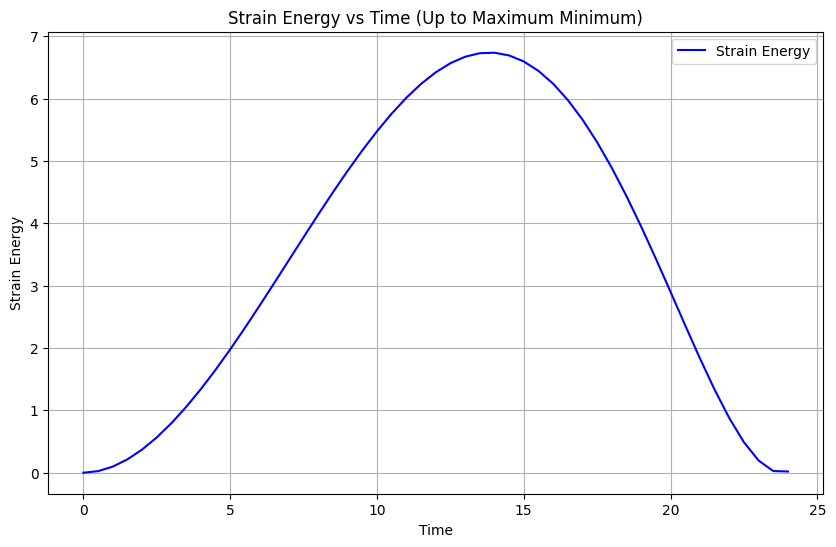

In [4]:
minima_indices, _ = find_peaks([-e for e in energy_log])
max_idx = minima_indices[np.argmax(t_log[minima_indices])]
print(f"Time of maximum energy minimum: {t_log[max_idx]}, Energy at that time: {energy_log[max_idx]}")
t_log_filtered = t_log[:max_idx+1]
energy_log_filtered = energy_log[:max_idx+1]

maxima_indices, _ = find_peaks(energy_log_filtered)
print(f"Times of energy maxima: {t_log_filtered[maxima_indices]}, Energies at those times: {energy_log_filtered[maxima_indices]}")

plt.figure(figsize=(10, 6))
plt.plot(t_log_filtered, energy_log_filtered, label='Strain Energy', color='blue')
plt.title('Strain Energy vs Time (Up to Maximum Minimum)')
plt.xlabel('Time')
plt.ylabel('Strain Energy')
plt.grid()
plt.legend()
plt.show()